# 07 - Extensions (Phase 5)

The core model answers one yes/no question: *will this bus be more than 5 minutes late at this timepoint?*
Agency users ask more than that. This notebook answers five follow-up questions with the same data and pipeline:

| # | Question (user) | Method | Code |
|---|---|---|---|
| 1 | Does delay **carry along a trip**, and do buses recover? (dispatcher, planner) | descriptive propagation analysis | `src/extensions/propagation.py` |
| 2 | Which segments are **chronically** late, and how much running time is missing? (planner) | persistent-segment detection + out-of-time check | `src/extensions/chronic.py` |
| 3 | **How late** - on time, minor, moderate or major? (dispatcher, rider comms) | 4-class XGBoost | `src/extensions/severity.py` |
| 4 | **How many minutes** late, with an interval? (rider comms) | XGBoost median + 80 % quantile interval | `src/extensions/regression.py` |
| 5 | Will buses **bunch**? (dispatcher) | bunching labels from headways + XGBoost | `src/extensions/bunching.py` |

> **What** -> **Why** -> **How** -> **Result** -> **Finding** -> **Decision**

**Protocol for the models (decision 19 in the decision log):** train on a stratified 2 M-row sample of Jan-Aug, early-stop on 300 k rows of
Sep-Oct, score the full Nov-Dec test period once. Tree settings are re-used from the Phase 3 Optuna search (no new tuning), so the numbers
are slightly conservative compared with the Phase 3 models, which were refitted on all of Jan-Oct.

In [1]:
import sys, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import REPORTS, FIG_DIR, SEVERITY_BINS, SEVERITY_LABELS
EXT = REPORTS / 'ext'
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 200, 'display.max_columns', 30)
def save(n): plt.tight_layout(); plt.savefig(FIG_DIR / f'p5_{n}.png', bbox_inches='tight'); plt.show()
def rd(n, **k): return pd.read_csv(EXT / f'{n}.csv', **k)
print(sorted(p.name for p in EXT.iterdir()))

['bunching_by_hour.csv', 'bunching_by_position.csv', 'bunching_by_route_id.csv', 'bunching_by_vs_delay.csv', 'bunching_importance.csv', 'bunching_metrics.csv', 'chronic_adjustments.csv', 'chronic_by_route.csv', 'chronic_segments.csv', 'chronic_summary.csv', 'prop_bus_to_bus.csv', 'prop_growth.csv', 'prop_late_start.csv', 'prop_overall.csv', 'prop_recovery_period.csv', 'prop_recovery_route.csv', 'prop_segment_added.csv', 'prop_transition.csv', 'regression_by_band_operational.csv', 'regression_by_band_planning.csv', 'regression_conformal.csv', 'regression_conformal_by_route.csv', 'regression_metrics.csv', 'regression_sample_operational.parquet', 'regression_sample_planning.parquet', 'severity_confusion_operational.csv', 'severity_confusion_planning.csv', 'severity_metrics.csv']


## 1. Delay propagation along the trip
**What:** how a bus's delay at one timepoint relates to its delay at the next, how delay grows along the route, and how often a late bus recovers.
**Why:** the operational model's biggest gain comes from `prev_tp_delay` (Phase 4: 24.9 % of SHAP importance). This section shows the
mechanism behind that, and tells dispatchers *when* intervening is worth it (if late buses rarely recover, act early).
**How:** all 2025 stop events, ordered within each trip by `time_point_order`. *Recovery* = late (> 5 min) at one timepoint and not late
at the next. Bus-to-bus: correlation of this bus's delay with the delay of the previous bus at the same stop.

corr_prev_tp             0.921
recovery_rate_overall    0.119
p_stay_late              0.881
p_become_late            0.068


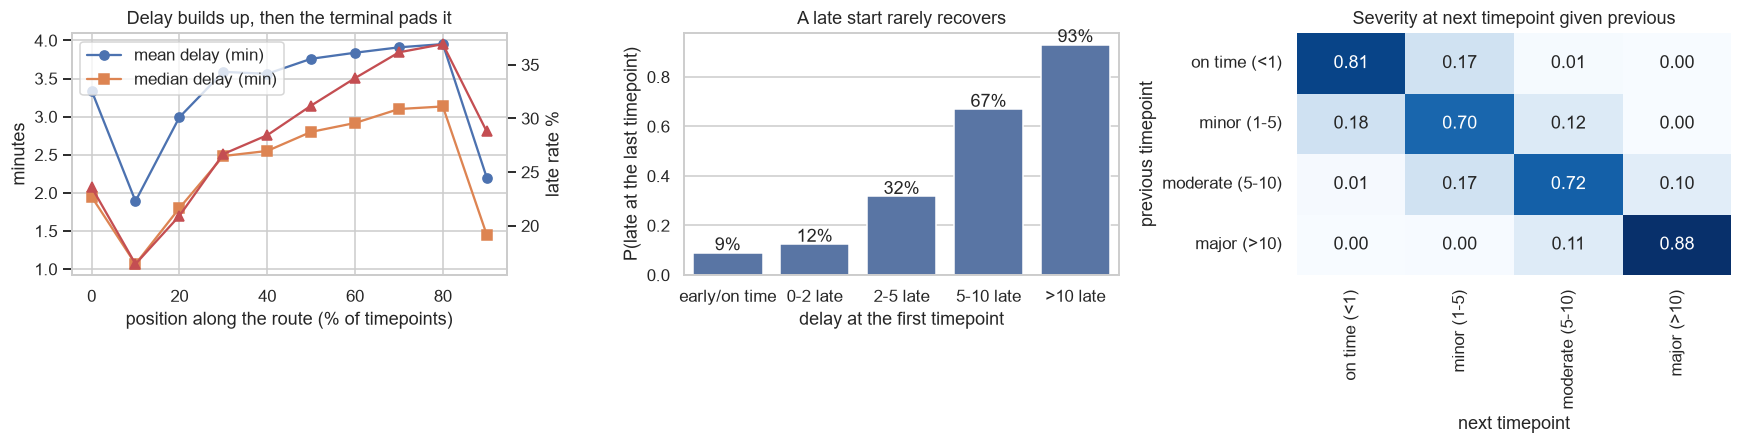

,start_band,trips,p_late_at_end,mean_end_delay
0,early/on time,230810,0.089935,-2.340942
1,0-2 late,486091,0.124384,-0.522524
2,2-5 late,206175,0.317235,2.779659
3,5-10 late,115749,0.669129,7.324334
4,>10 late,63285,0.930284,15.739292


In [2]:
ov = rd('prop_overall', index_col=0).iloc[:, 0]
print(ov.round(3).to_string())
g = rd('prop_growth'); ls = rd('prop_late_start'); tr = rd('prop_transition', index_col=0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(g.pos_decile, g.mean_delay, marker='o', label='mean delay (min)'); ax[0].plot(g.pos_decile, g.median_delay, marker='s', label='median delay (min)')
a2 = ax[0].twinx(); a2.plot(g.pos_decile, g.late_rate * 100, color='C3', marker='^', label='late rate %'); a2.set_ylabel('late rate %'); a2.grid(False)
ax[0].set(xlabel='position along the route (% of timepoints)', ylabel='minutes', title='Delay builds up, then the terminal pads it'); ax[0].legend(loc='upper left')
sns.barplot(data=ls, x='start_band', y='p_late_at_end', ax=ax[1], color='C0')
for i, v in enumerate(ls.p_late_at_end): ax[1].text(i, v + 0.01, f'{v:.0%}', ha='center')
ax[1].set(xlabel='delay at the first timepoint', ylabel='P(late at the last timepoint)', title='A late start rarely recovers')
sns.heatmap(tr, annot=True, fmt='.2f', cmap='Blues', ax=ax[2], cbar=False)
ax[2].set(title='Severity at next timepoint given previous', xlabel='next timepoint', ylabel='previous timepoint')
save('propagation')
ls

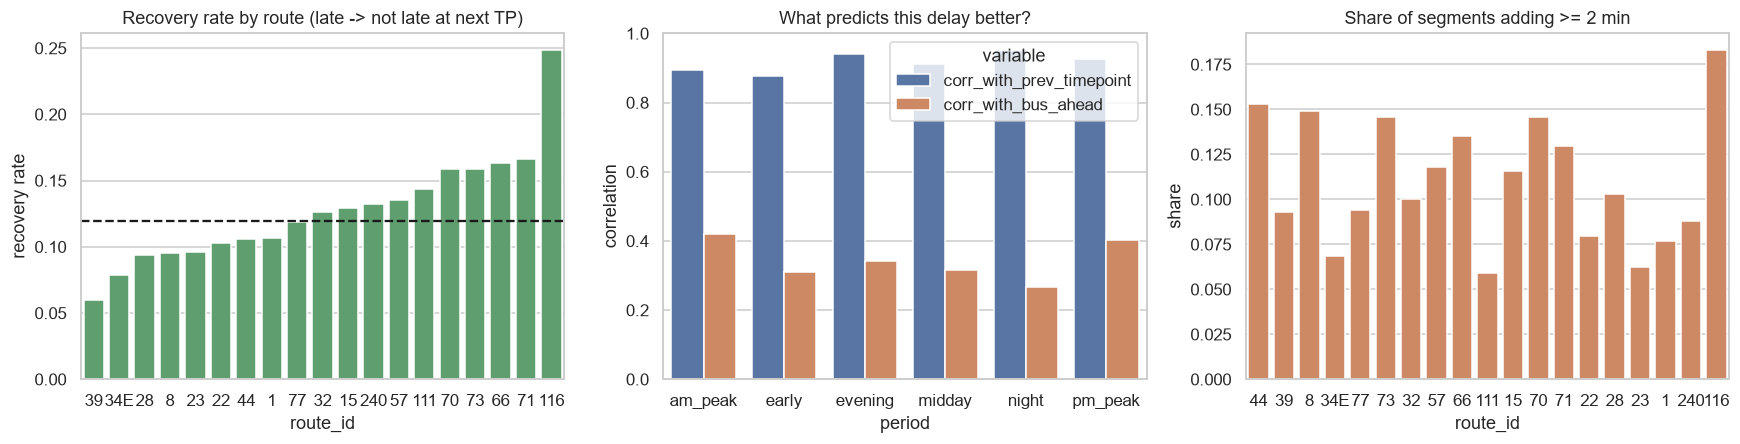

 period  late_events  recovery_rate
am_peak       377569          0.133
  early       143254          0.146
evening       484252          0.105
 midday       785639          0.123
  night       225961          0.103
pm_peak       503449          0.117


In [3]:
rp = rd('prop_recovery_period'); rr = rd('prop_recovery_route', dtype={'route_id': str}); bb = rd('prop_bus_to_bus'); sa = rd('prop_segment_added', dtype={'route_id': str})
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.barplot(data=rr.sort_values('recovery_rate'), x='route_id', y='recovery_rate', ax=ax[0], color='C2')
ax[0].axhline(ov['recovery_rate_overall'], ls='--', c='k'); ax[0].set(title='Recovery rate by route (late -> not late at next TP)', ylabel='recovery rate')
b = bb.melt(id_vars='period', value_vars=['corr_with_prev_timepoint', 'corr_with_bus_ahead'])
sns.barplot(data=b, x='period', y='value', hue='variable', ax=ax[1]); ax[1].set(title='What predicts this delay better?', ylabel='correlation')
sns.barplot(data=sa, x='route_id', y='share_segments_adding_2min', ax=ax[2], color='C1')
ax[2].set(title='Share of segments adding >= 2 min', ylabel='share')
save('propagation_recovery')
print(rp.round(3).to_string(index=False))

**Result**
* Delay at one timepoint correlates **0.92** with the delay at the next timepoint of the same trip.
* Once a bus is > 5 min late, it is still late at the next timepoint **88.1 %** of the time; only **11.9 %** recover.
  An on-time bus becomes late at the next timepoint only 6.8 % of the time.
* A trip that leaves its first timepoint **> 10 min late arrives late at the end 93 %** of the time (5-10 min: 67 %; on time: 9 %).
* Delay builds over the trip: median delay 1.1 min at 10 % of the route -> 3.1 min at 70-80 %; late rate 16 % -> 37 %. At the last decile it
  falls back to 1.5 min / 29 % because the terminal has schedule padding.
* Recovery is lowest on route **39 (6.0 %)**, 34E (7.9 %) and 28 (9.4 %), highest on 116 (24.9 %). By period it is lowest in the evening
  (10.5 %) and at night (10.3 %), highest early morning (14.6 %).
* The previous timepoint of the same bus explains a delay far better (r = 0.88-0.95) than the bus ahead at the same stop (r = 0.27-0.42).
  The bus-ahead link is strongest in the peaks (0.42 AM, 0.40 PM), when crowding spreads from bus to bus.

**Finding.** Delay is highly persistent and accumulates; recovery is the exception. This is the mechanism behind the operational model's
0.98 AUC and behind `prev_tp_delay` being its top SHAP feature. Recovery does not come from driving faster but from padding at the terminal.

**Decision.** (1) The dispatcher alert should act at the **first** timepoints of a trip: after a > 10 min late start, 93 % of trips end
late, so later intervention is too late. (2) The website shows recovery by route so planners see where padding is missing (39, 34E, 28).
(3) The live model uses the bus's own previous-timepoint delay as the main signal and the bus ahead only as context, as the correlations
suggest.

## 2. Chronic delay segments (planner's fix-list)
**What:** segments (route x direction x timepoint) that are late consistently, not just in a bad week.
**Why:** planners can change running times, stop spacing or bus priority only in a few places per schedule change; they need a ranked,
*persistent* list, and they need to know whether a segment **creates** delay or only **inherits** it from upstream.
**How:** Jan-Oct 2025. Chronic = late rate >= 1.5 x network average in >= 80 % of months. Verified out of time on Nov-Dec. *Added delay* =
delay here minus delay at the previous timepoint (median per segment). Running-time suggestion = median added delay per period, for chronic
segments only.

segments                      371.000
chronic_segments               29.000
network_late_rate_janoct        0.296
spearman_janoct_vs_novdec       0.842
top20_still_top_quartile_%     90.000
chronic_late_rate_test          0.479
other_late_rate_test            0.252


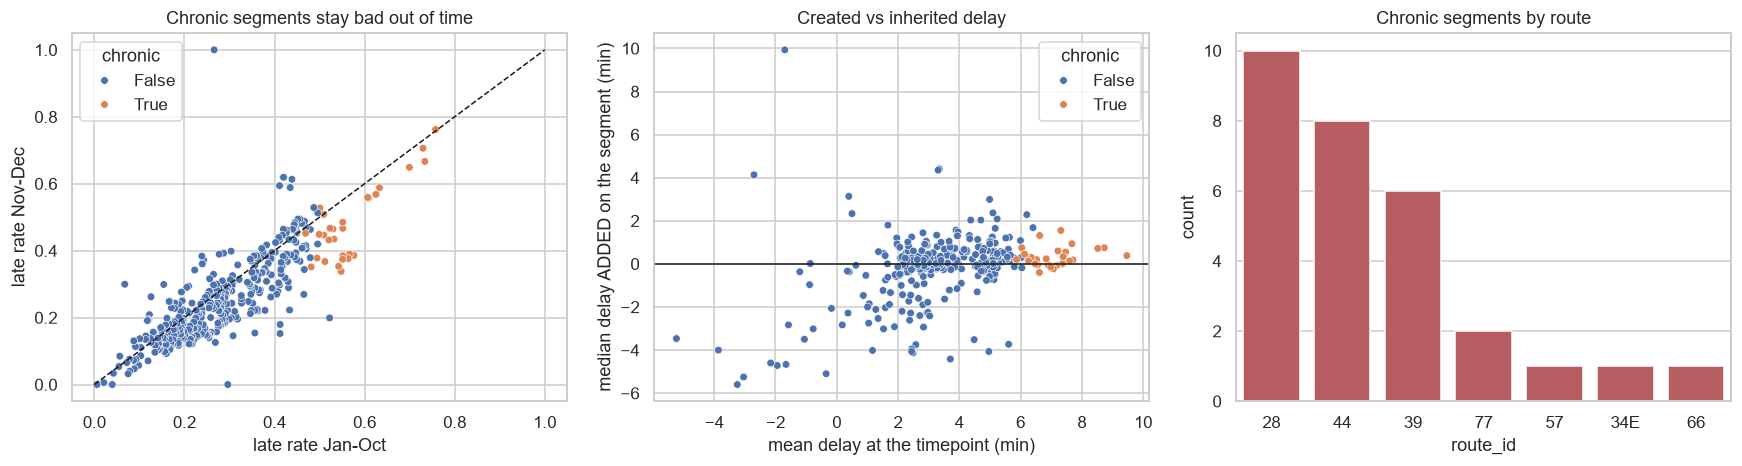

chronic segments: 29 | median mean_delay 6.99 min | median added 0.23 min | share adding >= 1 min: 7 %
suggested additions (chronic segment x period): 171 | > 0: 106 | >= 1 min: 20 | max 2.3 min


,route_id,direction_id,stop_id,period,n,median_added,late_rate,suggest_add_min
0,44,Inbound,396,pm_peak,2468,2.33,0.73,2.3
1,44,Outbound,40001,night,1086,1.97,0.84,2.0
2,44,Inbound,396,am_peak,2305,2.02,0.70,2.0
3,44,Outbound,64000,midday,3514,1.95,0.52,2.0
4,44,Outbound,40001,early,990,1.87,0.70,1.9
5,44,Outbound,64000,am_peak,2438,1.55,0.55,1.6
6,44,Inbound,396,midday,3682,1.63,0.59,1.6
7,57,Inbound,937,pm_peak,5522,1.48,0.60,1.5
8,28,Inbound,396,evening,5365,1.45,0.72,1.5
9,57,Inbound,937,early,2167,1.28,0.46,1.3


In [4]:
cs = rd('chronic_summary', index_col=0).iloc[:, 0]; print(cs.round(3).to_string())
seg = rd('chronic_segments', dtype={'route_id': str, 'stop_id': str}); cr = rd('chronic_by_route', dtype={'route_id': str})
adj = rd('chronic_adjustments', dtype={'route_id': str, 'stop_id': str})
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ok = seg.dropna(subset=['late_rate_test'])
sns.scatterplot(data=ok, x='late_rate', y='late_rate_test', hue='chronic', ax=ax[0], s=25)
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set(xlabel='late rate Jan-Oct', ylabel='late rate Nov-Dec', title='Chronic segments stay bad out of time')
sns.scatterplot(data=seg, x='mean_delay', y='median_added', hue='chronic', ax=ax[1], s=25)
ax[1].axhline(0, c='k', lw=1); ax[1].set(xlabel='mean delay at the timepoint (min)', ylabel='median delay ADDED on the segment (min)', title='Created vs inherited delay')
sns.barplot(data=cr[cr.chronic > 0], x='route_id', y='chronic', ax=ax[2], color='C3'); ax[2].set(title='Chronic segments by route', ylabel='count')
save('chronic')
ch = seg[seg.chronic]
print('chronic segments:', len(ch), '| median mean_delay %.2f min | median added %.2f min | share adding >= 1 min: %.0f %%' % (
      ch.mean_delay.median(), ch.median_added.median(), (ch.median_added >= 1).mean() * 100))
print('suggested additions (chronic segment x period):', len(adj), '| > 0: %d | >= 1 min: %d | max %.1f min' % (
      (adj.suggest_add_min > 0).sum(), (adj.suggest_add_min >= 1).sum(), adj.suggest_add_min.max()))
adj.head(10).round(2)

**Result**
* **29 of 371** segments (7.8 %) are chronic: late >= 1.5 x the network average (29.6 %) in >= 80 % of the months Jan-Oct. Their late rate
  is 47-76 %.
* **Out-of-time check:** the segment ranking from Jan-Oct and Nov-Dec agrees with Spearman rho = **0.84**; 18 of the top 20 (90 %) are still
  in the top quartile in Nov-Dec. On the test months chronic segments are late **47.9 %** of the time vs **25.2 %** for all others.
* Concentrated on three routes: **28 (10 segments), 44 (8), 39 (6)**; 77 has 2, 57, 34E and 66 one each; the other 12 routes none.
* **Inherited, not created:** chronic segments have a median delay of 7.0 min at the timepoint, but the median delay *added* on the segment
  itself is only **0.23 min**; only 2 of 29 add >= 1 min. Non-chronic segments add -0.01 min (they slightly recover).
* Running-time suggestions (chronic segment x period, median added delay): 171 combinations, 106 with a positive addition, 20 with >= 1 min,
  maximum **2.3 min** (route 44 inbound at stop 396, PM peak). Most of the top suggestions are on route 44.

**Finding.** The fix-list is stable over time, so it is actionable. But most chronic segments are late because the bus *arrives* late
from upstream, not because the segment's own running time is too short. Adding running time at the chronic segment would treat the symptom.

**Decision.** The Planner Insights page shows both columns, *mean delay* and *added delay*, so a planner can separate **creating**
segments (fix the running time there, e.g. route 44 around stops 396 / 40001 / 64000) from **inheriting** segments (fix upstream or the trip
start). The suggested additions are reported per period and include zeros, so they are never inflated.

## 3. Severity: how late? (4 classes)
**What:** on time (< 1 min), minor (1-5), moderate (5-10), major (> 10 min late).
**Why:** a 6-minute and a 25-minute delay are both "late" for the binary model, but a dispatcher acts very differently on them.
**How:** XGBoost `multi:softprob`. Baselines: **B0** = class of the stop's usual delay at this hour; for operational also **B1 persistence** =
the class the bus is in at the previous timepoint (computed below). Metrics: macro-F1 (imbalanced classes), quadratic-weighted kappa
(ordered classes), recall of *major*.

In [5]:
sev = rd('severity_metrics')
from src.encoding import load_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report
te = load_split('test', ['prev_tp_delay', 'severity'])
y = pd.Categorical(te.severity.astype(str), categories=SEVERITY_LABELS).codes
pers = pd.cut(te.prev_tp_delay.fillna(0) * 60, SEVERITY_BINS, labels=False, right=False).astype(int).values
rep = classification_report(y, pers, labels=range(4), target_names=SEVERITY_LABELS, output_dict=True, zero_division=0)
b1 = {'mode': 'operational', 'model': 'B1 persistence (prev timepoint class)', 'accuracy': accuracy_score(y, pers),
      'macro_f1': f1_score(y, pers, average='macro'), 'qw_kappa': cohen_kappa_score(y, pers, weights='quadratic'),
      **{f'recall_{c}': rep[c]['recall'] for c in SEVERITY_LABELS}, **{f'precision_{c}': rep[c]['precision'] for c in SEVERITY_LABELS}}
sev = pd.concat([sev, pd.DataFrame([b1])], ignore_index=True)
sev.to_csv(EXT / 'severity_metrics_with_persistence.csv', index=False)
print('test rows', len(te), '| class shares', np.bincount(y, minlength=4) / len(y))
cols = ['mode', 'model', 'accuracy', 'macro_f1', 'qw_kappa', 'recall_major', 'precision_major', 'auc_gt5_from_multiclass']
sev[cols].round(3)

test rows 1685083 | class shares [0.42352098 0.32596851 0.15757147 0.09293904]


,mode,model,accuracy,macro_f1,qw_kappa,recall_major,precision_major,auc_gt5_from_multiclass
0,planning,B0 hist-delay class,0.332,0.239,0.171,0.016,0.262,NaN
1,planning,XGB multi-class,0.506,0.360,0.292,0.103,0.341,0.732
2,operational,B0 hist-delay class,0.332,0.239,0.171,0.016,0.262,NaN
3,operational,XGB multi-class,0.819,0.814,0.864,0.801,0.928,0.976
4,operational,B1 persistence (prev timepoint class),0.739,0.737,0.801,0.763,0.871,NaN


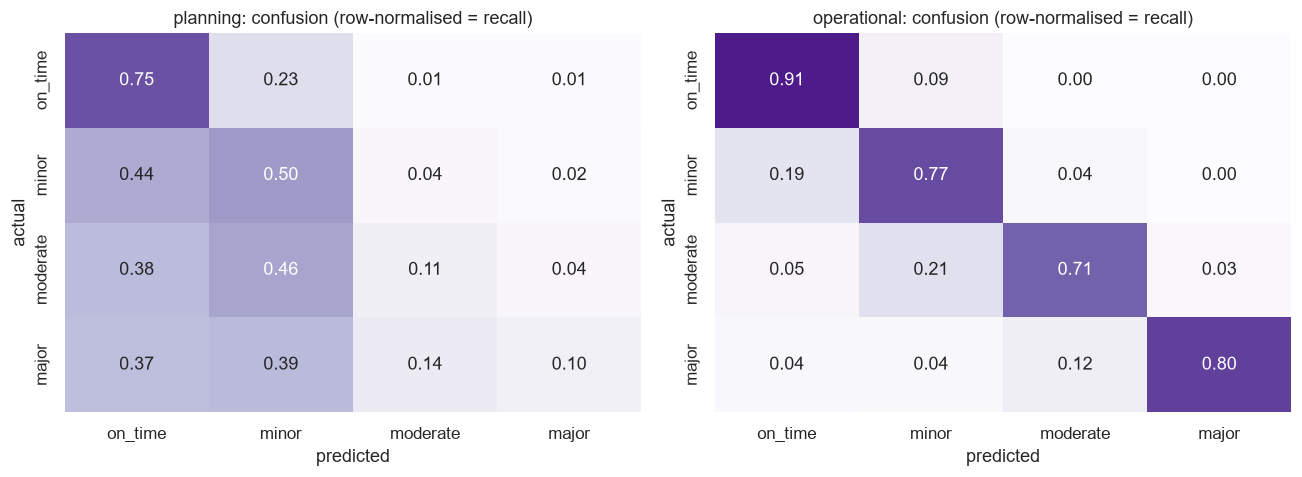

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, m in zip(ax, ('planning', 'operational')):
    cm = rd(f'severity_confusion_{m}', index_col=0)
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Purples', ax=a, cbar=False, vmin=0, vmax=1)
    a.set(title=f'{m}: confusion (row-normalised = recall)', xlabel='predicted', ylabel='actual')
save('severity_confusion')

**Result** (test Nov-Dec, 1.69 M stop events; class shares 42 % on time, 33 % minor, 16 % moderate, 9 % major)

| Mode | Model | Accuracy | Macro-F1 | QW kappa | Recall major | Precision major |
|---|---|---|---|---|---|---|
| planning | B0 usual delay class | 0.332 | 0.239 | 0.171 | 0.016 | 0.262 |
| planning | XGB 4-class | **0.506** | **0.360** | **0.292** | 0.103 | 0.341 |
| operational | B1 persistence | 0.739 | 0.737 | 0.801 | 0.763 | 0.871 |
| operational | XGB 4-class | **0.819** | **0.814** | **0.864** | **0.801** | **0.928** |

* Day-ahead, XGB improves on the baseline (+0.17 accuracy, +0.12 macro-F1) but finds only **10 %** of major delays; most moderate and major
  events are predicted as on time or minor.
* With live information, XGB beats the strong persistence baseline on every metric: +8 points accuracy, +0.06 kappa, and major delays are
  found 80 % of the time with 93 % precision.
* Consistency check: P(moderate) + P(major) used as a "> 5 min" score gives AUC 0.732 (planning) and **0.976** (operational), close to the
  binary models (0.755 / 0.978, which were refitted on all of Jan-Oct).
* The operational model used all 1,000 trees (no early stop), i.e. it was still improving slowly.

**Finding.** *How late* is largely unpredictable a day ahead: large delays are caused by incidents the planning features cannot see.
In real time it is well predictable, because severity is persistent (the transition matrix in section 1 shows 88 % of major delays stay
major) and the model adds slack, the bus ahead and history on top of persistence.

**Decision.** Severity is shown for the **operational** mode only (dispatcher: "likely major delay"). For planning the website keeps the
binary probability and does not show a severity class, which would be misleading at 10 % recall of major delays. The 1,000-tree cap is
kept (decision 29): the planning run took 17 min and the operational run 20 min; more trees would cost time for a secondary model whose
binary counterpart already reaches AUC 0.978.

## 4. Delay in minutes, with an 80 % interval
**What:** a point prediction of the delay (minutes) and an interval that should contain the true delay 80 % of the time.
**Why:** rider messages are better as "expected 3-9 min late" than as "62 % chance of being late".
**How:** XGBoost with absolute-error loss (predicts the conditional **median**: robust to the long tail of 30-60 min incidents) and a
multi-quantile XGBoost (10 % / 90 %) on 1 M random training rows. Target clipped to [-10, 60] min. Baselines: B0 = stop's usual delay at
this hour; B1 (operational) = persistence, the delay at the previous timepoint.

       mode                           model   MAE  RMSE  median_AE  within_2min_%  within_5min_%  interval80_coverage_%  interval80_median_width_min
   planning        B0 stop-hour usual delay 4.386 5.902      3.337         31.358         67.185                    NaN                          NaN
   planning                      XGB median 3.590 5.307      2.400         43.494         76.914                 75.475                       10.321
operational        B0 stop-hour usual delay 4.386 5.902      3.337         31.358         67.185                    NaN                          NaN
operational B1 persistence (prev timepoint) 1.713 2.949      1.033         74.546         94.472                    NaN                          NaN
operational                      XGB median 1.078 2.094      0.636         89.013         97.343                 78.338                        2.910


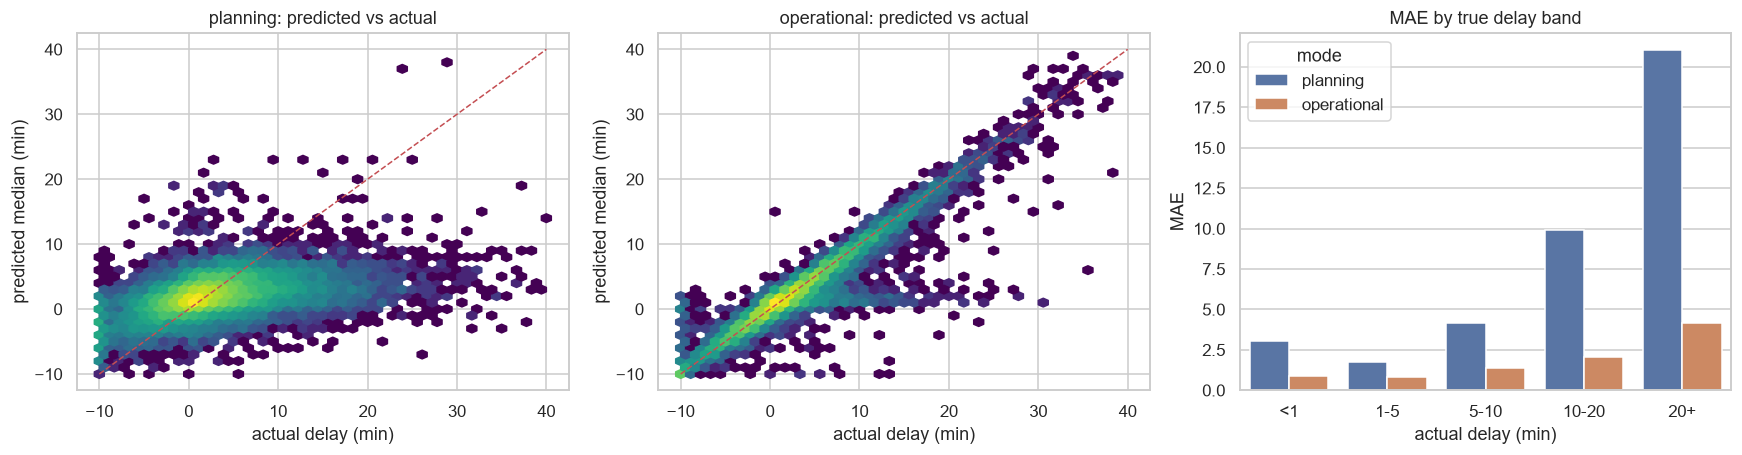

,band,n,MAE,bias,mode
0,<1,713668,3.05,2.76,planning
1,1-5,549284,1.72,-0.35,planning
2,5-10,265521,4.15,-3.93,planning
3,10-20,132164,9.92,-9.86,planning
4,20+,24446,21.04,-20.97,planning
0,<1,713668,0.87,0.35,operational
1,1-5,549284,0.84,-0.32,operational
2,5-10,265521,1.37,-0.91,operational
3,10-20,132164,2.05,-1.58,operational
4,20+,24446,4.16,-3.38,operational


In [7]:
reg = rd('regression_metrics'); print(reg.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for i, m in enumerate(('planning', 'operational')):
    s = pd.read_parquet(EXT / f'regression_sample_{m}.parquet')
    s['y'] = s.delay_min.clip(-10, 60)
    ax[i].hexbin(s.y, s.pred, gridsize=45, bins='log', cmap='viridis', extent=(-10, 40, -10, 40))
    ax[i].plot([-10, 40], [-10, 40], 'r--', lw=1); ax[i].set(xlabel='actual delay (min)', ylabel='predicted median (min)', title=f'{m}: predicted vs actual')
bands = pd.concat([rd(f'regression_by_band_{m}').assign(mode=m) for m in ('planning', 'operational')])
sns.barplot(data=bands, x='band', y='MAE', hue='mode', ax=ax[2]); ax[2].set(title='MAE by true delay band', xlabel='actual delay (min)')
save('regression')
bands.round(2)

In [8]:
# interval calibration by route (operational): is the 80 % interval honest everywhere?
rows = []
for m in ('planning', 'operational'):
    s = pd.read_parquet(EXT / f'regression_sample_{m}.parquet'); s['y'] = s.delay_min.clip(-10, 60)
    s['inside'] = (s.y >= s.lo) & (s.y <= s.hi)
    rows.append(s.groupby(s.route_id.astype(str)).inside.mean().rename(m))
cov = pd.concat(rows, axis=1).round(3)
print('coverage of the 80 % interval by route (20 k test sample):'); print(cov.describe().round(3).loc[['min', '50%', 'max']])

coverage of the 80 % interval by route (20 k test sample):
     planning  operational
min     0.668        0.746
50%     0.756        0.783
max     0.787        0.812


### 4b. Fixing the under-coverage: conformalized quantile regression (CQR)
**Why:** the raw 80 % interval covers less than 80 % of test delays. Quantile trees fitted on a sub-sample with early stopping are known to
under-cover. **How** (`src/extensions/conformal.py`, Romano et al. 2019): on the validation months (Sep-Oct) compute the conformity score
E = max(lo - y, y - hi). Its 80 % quantile Q is added to both ends of every interval. The guarantee holds only if validation and test are
exchangeable, and autumn vs winter are not exactly exchangeable, so we check coverage on Nov-Dec.

       mode  Q_min  valid_raw_coverage_%  test_raw_coverage_%  test_raw_median_width  test_cal_coverage_%  test_cal_median_width
   planning  0.327                76.914               75.475                 10.321               78.887                 10.975
operational  0.034                78.848               78.338                  2.910               79.573                  2.978


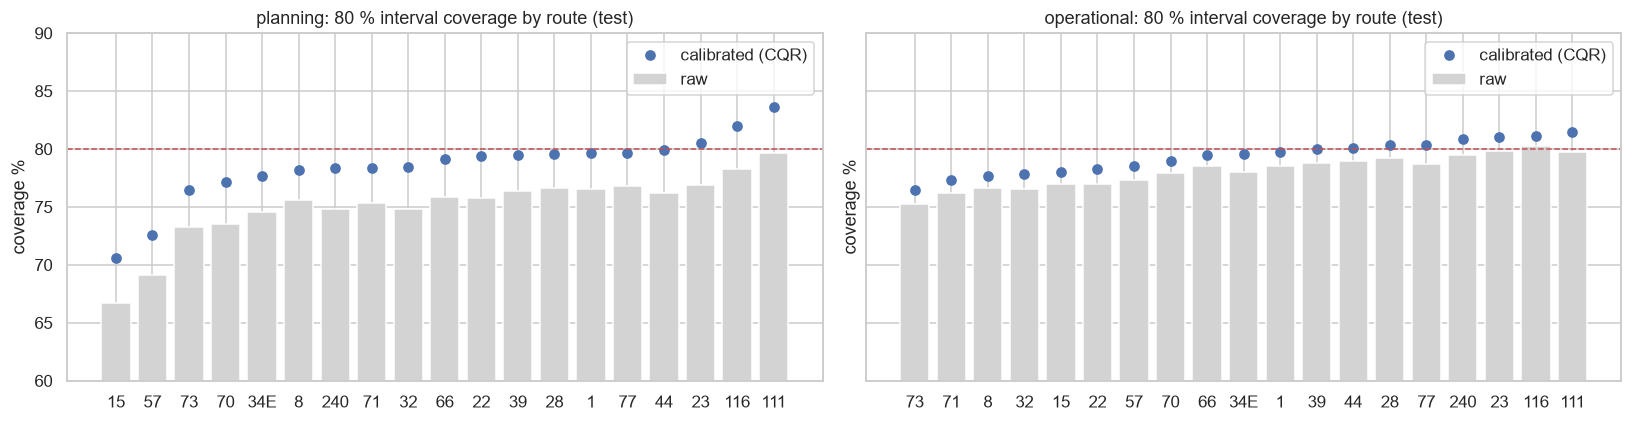

mode      operational  planning
route_id                       
15               78.0      70.6
57               78.5      72.5
73               76.5      76.5
70               79.0      77.2


In [9]:
conf = rd('regression_conformal'); print(conf.round(3).to_string(index=False))
cr = rd('regression_conformal_by_route', dtype={'route_id': str})
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for i, m in enumerate(('planning', 'operational')):
    d = cr[cr['mode'] == m].sort_values('cal')
    ax[i].bar(d.route_id, d.raw, color='lightgray', label='raw'); ax[i].plot(d.route_id, d.cal, 'o', color='C0', label='calibrated (CQR)')
    ax[i].axhline(80, color='r', ls='--', lw=1); ax[i].set(title=f'{m}: 80 % interval coverage by route (test)', ylim=(60, 90), ylabel='coverage %'); ax[i].legend()
save('conformal')
print(cr.pivot(index='route_id', columns='mode', values='cal').round(1).sort_values('planning').head(4))

**Result** (test Nov-Dec, 1.69 M stop events, target clipped to [-10, 60] min)

| Mode | Model | MAE (min) | RMSE | Median AE | Within 2 min | Within 5 min | 80 % interval: coverage / median width |
|---|---|---|---|---|---|---|---|
| planning | B0 stop-hour usual delay | 4.39 | 5.90 | 3.34 | 31.4 % | 67.2 % | - |
| planning | XGB median | **3.59** | **5.31** | **2.40** | **43.5 %** | **76.9 %** | raw 75.5 % / 10.3 min; CQR **78.9 %** / 11.0 min |
| operational | B1 persistence | 1.71 | 2.95 | 1.03 | 74.5 % | 94.5 % | - |
| operational | XGB median | **1.08** | **2.09** | **0.64** | **89.0 %** | **97.3 %** | raw 78.3 % / 2.91 min; CQR **79.6 %** / 2.98 min |

* Day-ahead, XGB cuts the error of the "usual delay" baseline by 18 % (MAE 4.39 -> 3.59 min). With live data it cuts the error of
  persistence by 37 % (1.71 -> 1.08 min), and 89 % of predictions are within 2 minutes.
* Error by true delay band: the planning model **shrinks towards typical delays**. Its bias is +2.8 min for buses that were on time
  (< 1 min) and -9.9 / -21.0 min for buses 10-20 / 20+ min late. The operational model has MAE 0.84-0.87 min below 5 min and 4.2 min
  for 20+ min delays (bias -3.4).
* Intervals: the raw quantile interval under-covers. CQR calibration (section 4b) adds +0.33 min (planning) and +0.03 min (operational)
  to both ends and lifts coverage to 78.9 % / 79.6 %. It stays just below 80 % because the calibration months (autumn) and the test months
  (winter) differ. By route, planning coverage after CQR runs from 70.6 % (route 15) and 72.5 % (route 57) to 83.6 % (route 111);
  operational runs from 76.5 % (route 73) to 81.4 % (route 111).

**Finding.** Minutes-late is useful in real time (median error ~40 s, interval ~3 min wide). A day ahead, the median prediction is only a
"typical delay": it cannot anticipate large incidents (the same conclusion as severity), and the honest interval is about 11 min wide.

**Decision (31).** Rider messages use the **operational** median with the CQR-calibrated interval ("expected 4-7 min late"). Planning
shows the probability, not a minutes estimate. Routes 15 and 57 are flagged as having intervals that are too narrow day-ahead.
Conformal calibration was chosen over refitting because it costs seconds, needs no new training and has a known guarantee.

## 5. Bus bunching
**What:** *bunched* = actual headway < 25 % of the scheduled headway; *big gap* = > 150 % (decision 20).
**Why:** bunching is the visible symptom of unreliable service on frequent routes: two buses arrive together, then nobody comes. A dispatcher
can hold the second bus if bunching is predicted early.
**How:** headways from the cleaned MBTA file joined on (service_date, half_trip_id, time_point_order). Descriptive rates by route, hour and
position; models: B0 = the gap-ratio feature itself as a score, operational XGB, planning XGB. The sign of B0 needed a diagnosis
(cell below, decision 30).

           model        mode  roc_auc  pr_auc  base_rate  coverage_%  trees
B0 gap ratio (+) operational    0.695   0.228      0.073      99.026    NaN
             XGB operational    0.915   0.444      0.073     100.000  802.0
             XGB    planning    0.726   0.158      0.073     100.000   89.0


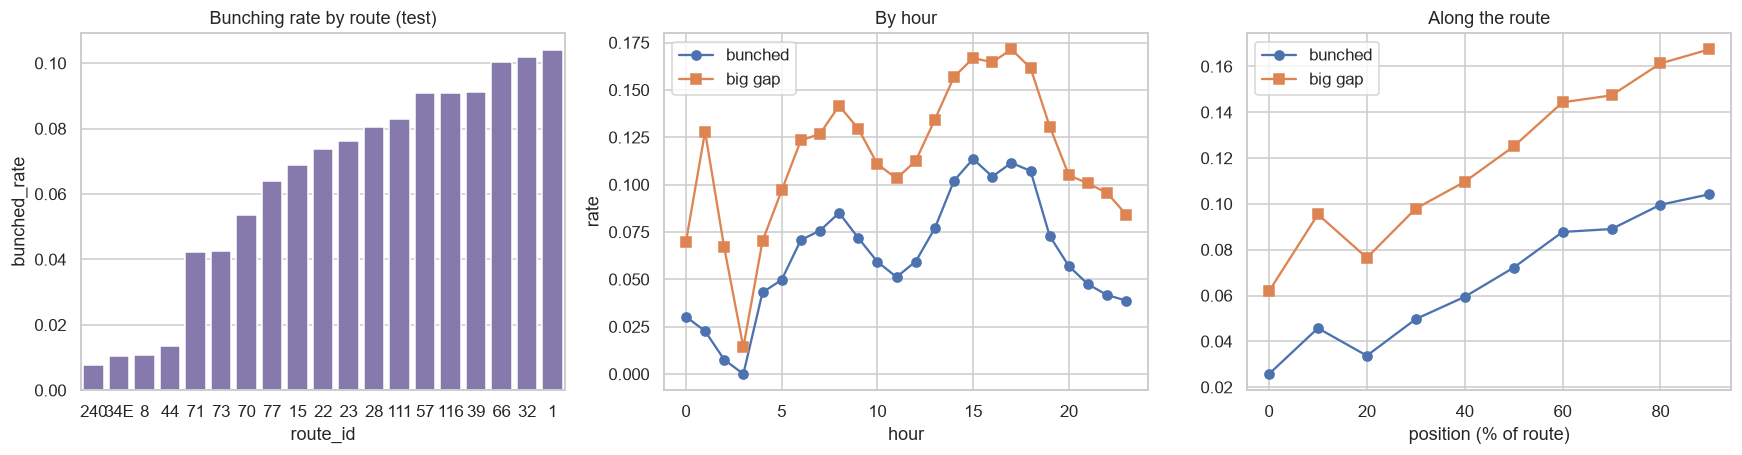

   bunched  mean_delay  late_rate
0        0       2.379      0.239
1        1       3.509      0.355
                        0
prev_bus_gap_ratio  346.0
standard_type       203.0
stop_pos            168.0
am_peak             162.0
point_type          151.0
prev_bus_delay      146.0
scheduled_headway   141.0
prev_tp_delay       125.0


In [10]:
bm = rd('bunching_metrics'); print(bm.round(3).to_string(index=False))
br = rd('bunching_by_route_id', dtype={'route_id': str}); bh = rd('bunching_by_hour'); bp = rd('bunching_by_position'); bv = rd('bunching_by_vs_delay')
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.barplot(data=br.sort_values('bunched_rate'), x='route_id', y='bunched_rate', ax=ax[0], color='C4'); ax[0].set(title='Bunching rate by route (test)')
ax[1].plot(bh.hour, bh.bunched_rate, marker='o', label='bunched'); ax[1].plot(bh.hour, bh.big_gap_rate, marker='s', label='big gap')
ax[1].set(title='By hour', xlabel='hour', ylabel='rate'); ax[1].legend()
ax[2].plot(bp.pos_decile, bp.bunched_rate, marker='o', label='bunched'); ax[2].plot(bp.pos_decile, bp.big_gap_rate, marker='s', label='big gap')
ax[2].set(title='Along the route', xlabel='position (% of route)'); ax[2].legend()
save('bunching')
print(bv.round(3)); print(rd('bunching_importance', index_col=0).iloc[:8].round(0))

### 5b. Diagnosis: why a LARGE gap ratio predicts bunching
The first run scored B0 as `-prev_bus_gap_ratio` (assuming "small gap now -> bunched later") and obtained ROC-AUC **0.305**, i.e. worse
than random, so the relation runs the other way. In `src/features.py` the feature is the time since the last bus that has **already passed the
target stop**, divided by the planned headway. If the direct leader is close, it has *not* passed the target stop yet and is skipped,
so the feature then describes the bus two ahead and is large. The cell checks this on all test rows.

rows 1,599,590  AUC(-ratio) = 0.305   AUC(+ratio) = 0.695


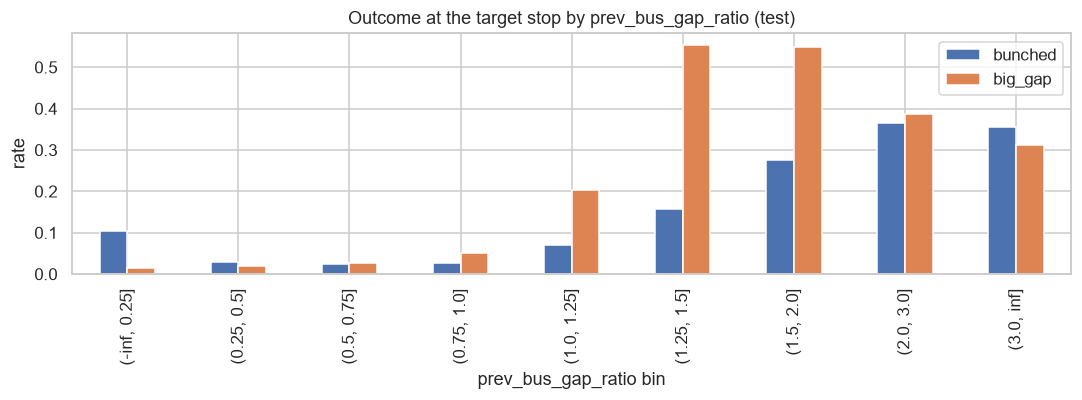

,rows,bunched,big_gap,median_headway_ratio
prev_bus_gap_ratio,,,,
"(-inf, 0.25]",142779,0.103,0.016,0.531
"(0.25, 0.5]",219712,0.028,0.018,0.742
"(0.5, 0.75]",347825,0.024,0.026,0.921
"(0.75, 1.0]",439183,0.026,0.052,1.064
"(1.0, 1.25]",188286,0.071,0.203,1.301
"(1.25, 1.5]",97325,0.157,0.555,1.539
"(1.5, 2.0]",98085,0.276,0.550,1.712
"(2.0, 3.0]",40748,0.364,0.387,0.469
"(3.0, inf]",10069,0.355,0.313,0.474


In [11]:
from sklearn.metrics import roc_auc_score
from src.encoding import load_split
from src.extensions.bunching import headways, attach
te = attach(load_split('test', ['service_date', 'half_trip_id', 'time_point_order', 'prev_bus_gap_ratio']), headways())
s = te.prev_bus_gap_ratio.fillna(te.prev_bus_gap_ratio.median())
print(f"rows {len(te):,}  AUC(-ratio) = {roc_auc_score(te.bunched, -s):.3f}   AUC(+ratio) = {roc_auc_score(te.bunched, s):.3f}")
bins = pd.cut(te.prev_bus_gap_ratio, [-np.inf, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 2, 3, np.inf])
u = te.groupby(bins, observed=True).agg(rows=('bunched', 'size'), bunched=('bunched', 'mean'), big_gap=('big_gap', 'mean'),
                                         median_headway_ratio=('hw_ratio', 'median'))
u.to_csv(EXT / 'bunching_by_gap_ratio.csv')
ax = u[['bunched', 'big_gap']].plot(kind='bar', figsize=(10, 3.8), title='Outcome at the target stop by prev_bus_gap_ratio (test)')
ax.set(xlabel='prev_bus_gap_ratio bin', ylabel='rate'); save('bunching_gap_ratio')
del te; u.round(3)

**Result** (9.30 M headway events in 2025: 7.6 % bunched, 13.2 % big gap; test base rate 7.3 %)

| Model | ROC-AUC | PR-AUC (base 0.073) | Note |
|---|---|---|---|
| B0 gap-ratio feature, sign as first assumed (-ratio) | 0.305 | 0.071 | worse than random: wrong sign |
| B0 gap-ratio feature (+ratio, after diagnosis) | 0.695 | 0.228 | one feature, 99 % coverage |
| planning XGB | 0.726 | 0.158 | 89 trees |
| operational XGB | **0.915** | **0.444** | 802 trees; top feature `prev_bus_gap_ratio` |

* **Where and when:** the frequent routes bunch most: 1 (10.4 %), 32 (10.2 %), 66 (10.0 %). Low-frequency routes hardly bunch: 240, 34E, 8
  and 44 are around 1 %. Bunching grows steadily along the route, from 2.6 % in the first decile to 10.4 % in the last, the classic
  instability of bus headways. It peaks in the afternoon: 10-11 % between 14:00 and 18:00, against 8.5 % at 08:00.
* **Bunching and lateness:** bunched arrivals are more often late (35.5 % vs 23.9 %, mean delay 3.5 vs 2.4 min).
* **Diagnosis (5b, decision 30):** the gap-ratio feature has a **U-shaped** relation with bunching. Ratio <= 0.25 gives 10.3 % bunched,
  0.25-1 gives 2.4-2.8 %, and > 2 gives 35-36 % with a median headway ratio of 0.47. A large value means the direct leader has not
  passed the target stop yet (so it is close ahead), because the feature skips buses still en route. This explains the inverted
  baseline. It also exposed a **train/serve skew** in live mode, which measured the direct leader's gap; this was fixed (Chapter 10,
  `passed_bus_features`).

**Finding.** Bunching is predictable in real time: PR-AUC 0.444 is 6x the base rate, and the trees learn the U-shape that a single
threshold cannot. A day ahead it is only weakly predictable (PR-AUC 2x base), mainly *where* and *when* (route frequency, position,
afternoon peak).

**Decision.** Bunching stays an analysis and planning result, shown with the route, hour and position profiles. It is not a live alert
yet: at PR-AUC 0.44 a dispatcher alert would need a threshold study with MBTA staff, which we list as future work. The baseline was
corrected in `src/extensions/bunching.py` rather than silently reported as 1 - AUC.

## 6. Phase 5 summary

| Extension | Key result (test Nov-Dec) | Used in the website |
|---|---|---|
| Propagation | delay at consecutive timepoints correlates 0.92; once > 5 min late, 88 % stay late (only 12 % recover) | explains why the live model leans on `prev_tp_delay`; dispatcher guidance "act early" |
| Chronic segments | 29 of 371 segments are chronic (rank agreement train vs test 0.84); most *inherit* delay (median added 0.23 min) | Planner Insights: chronic list and running-time suggestions (max +2.3 min) |
| Severity | operational QWK 0.864, major delays recall 0.80 at precision 0.93; planning finds only 10 % of majors | Live Mode severity column (operational only, decision 29) |
| Minutes late | operational MAE 1.08 min (persistence 1.71), CQR interval coverage 79.6 % | Planner Insights table; rider message wording (decision 31) |
| Bunching | operational PR-AUC 0.444 (6x base); frequent routes, route end and afternoon bunch most | Planner Insights profiles; feature-definition fix in live mode (decision 30) |

**Overall finding.** The extensions repeat the main thesis result at a finer resolution. Real-time information makes *every* question
answerable (late or not, how late, how many minutes, bunched or not). Day-ahead features only give a reliable picture of *where and when*
risk is high. That is exactly the split between the planner pages (patterns) and the dispatcher pages (live predictions) of the website
built in Phase 6.

**Checks done in this phase:** every model has a naive baseline from the same information set; all numbers are on the untouched Nov-Dec
test months; one inverted baseline was found, diagnosed and fixed (decision 30); interval coverage was measured and calibrated
(decision 31).